# **Machine learning models: healthy or sick**

This notebook trains three models on the cleaned HCV data to predict whether a patient is healthy or sick. The models, their settings and the evaluation are the same as in `COM725/COM725_AE2_Omar_Al_Hajaj.ipynb`, so the two studies can be compared.

Two things differ from COM725. Outliers are kept, because in this data the extreme values belong to the sick patients (see `cleaning.ipynb`). The decision tree is trained on the original values and not on binned values, because the COM725 bins were written for a different set of columns.

# **Importing Libraries**

In [1]:
# importing necessary libraries / dependencies
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, QuantileTransformer
from sklearn.tree import DecisionTreeClassifier

pd.set_option('display.max_columns', None)

# **Loading the DataFrame**

In [2]:
# retrieving the cleaned dataset saved by cleaning.ipynb
df = pd.read_csv('hcv_median_imputed.csv')

# first 5 rows of the dataset
df.head()

,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,cat_num
0,Healthy,32.0,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0
1,Healthy,32.0,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0
2,Healthy,32.0,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0
3,Healthy,32.0,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0
4,Healthy,32.0,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0


# **Feature engineering**

FIB-4 was added to the COM725 data, but it needs a platelet count and this dataset does not have one. The AST/ALT ratio is used here instead, because it only needs two columns that are already in the data.

Sheth et al. (1998) found that the AST/ALT ratio is higher in chronic hepatitis C patients with cirrhosis (mean 1.06) than in those without (mean 0.60). Chicco and Jurman (2021) trained machine learning models on this same dataset and found AST and ALT to be the two most useful variables, which are the two values the ratio is made of.

- Sheth, S.G., Flamm, S.L., Gordon, F.D. and Chopra, S. (1998) 'AST/ALT ratio predicts cirrhosis in patients with chronic hepatitis C virus infection', *American Journal of Gastroenterology*, 93(1), pp. 44-48.
- Chicco, D. and Jurman, G. (2021) 'An ensemble learning approach for enhanced classification of patients with hepatitis and cirrhosis', *IEEE Access*, 9, pp. 24485-24498.

In [3]:
# engineering the AST/ALT ratio
df['ast_alt_ratio'] = df['AST'] / df['ALT']

# making sure the division did not create missing or infinite values
assert np.isfinite(df['ast_alt_ratio']).all()

# checking the new feature for each category
df.groupby('Category')['ast_alt_ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
Category,,,,,,,,
Cirrhosis,30.0,16.844175,17.037207,0.638298,6.541667,14.927027,20.582749,89.222222
Fibrosis,21.0,4.728592,7.358996,0.410853,0.809524,3.580311,5.411255,34.791667
Healthy,533.0,1.153575,0.761765,0.417443,0.853175,1.083333,1.319635,15.840000
Hepatitis,24.0,3.693453,2.299685,0.681818,2.739116,3.619549,4.463736,11.654676


# **Target engineering**

In [4]:
# grouping hepatitis, fibrosis and cirrhosis patients into one sick class
df['Target'] = np.where(df['Category'] == 'Healthy', 'Healthy', 'Sick')

# number of patients in each class
print(df['Target'].value_counts())

Target
Healthy    533
Sick        75
Name: count, dtype: int64


# **Machine learning training and modelling**

# Encoding and data preparation

In [5]:
# encoding sex into numeric values (f = 0, m = 1)
sex_encoder = LabelEncoder()
df['Sex'] = sex_encoder.fit_transform(df['Sex'])

# encoding the target into numeric values (Healthy = 0, Sick = 1)
target_encoder = LabelEncoder()
df['Target'] = target_encoder.fit_transform(df['Target'])
classes = target_encoder.classes_
print(classes)

['Healthy' 'Sick']


In [6]:
# defining training and target features
# Category and cat_num are dropped as they hold the diagnosis itself

X = df.drop(columns=['Category', 'cat_num', 'Target'])
y = df['Target']

# train - test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# checking the size of each set and the number of sick patients in it
print('Train:', X_train.shape, 'sick patients:', y_train.sum())
print('Test:', X_test.shape, 'sick patients:', y_test.sum())

Train: (486, 13) sick patients: 60
Test: (122, 13) sick patients: 15


# Logistic regression

In [7]:
# defining logistic regression pipeline
# n_quantiles is set to the number of training rows as it cannot be larger
log_pipeline = Pipeline([
    ('transformer', QuantileTransformer(
        n_quantiles=len(X_train),
        output_distribution='normal',
        random_state=42)),
    ('classifier', LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42))])

# training pipeline
log_pipeline.fit(X_train, y_train)

# testing pipeline
log_preds = log_pipeline.predict(X_test)

# evaluating predictions
log_results = classification_report(y_test, log_preds, target_names=classes)
print(log_results)

              precision    recall  f1-score   support

     Healthy       0.98      0.99      0.99       107
        Sick       0.93      0.87      0.90        15

    accuracy                           0.98       122
   macro avg       0.96      0.93      0.94       122
weighted avg       0.97      0.98      0.98       122



The model performs well, with 98% accuracy. It finds 13 of the 15 sick patients and wrongly flags 1 of the 107 healthy patients.

# Calibration plot - Logistic Regression

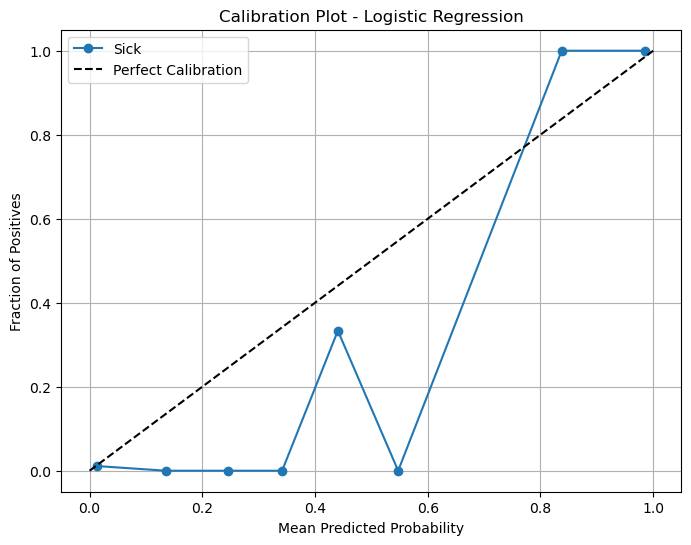

In [8]:
# getting predicted probabilities of the sick class from logistic regression
log_probs = log_pipeline.predict_proba(X_test)[:, 1]

# calculate calibration curve for the sick class
prob_true, prob_pred = calibration_curve(
    y_test,
    log_probs,
    n_bins=10,
    strategy='uniform'
)

# plotting calibration curve
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Sick')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Logistic Regression')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature distribution - logistic regression

Data preparation

In [9]:
# creating a copy of the test data
log_error_df = X_test.copy()

# adding actual and predicted classes
log_error_df['Actual_Class'] = y_test.values
log_error_df['Predicted_Class'] = log_preds

# checking if the prediction was correct or incorrect
log_error_df['Prediction_Result'] = np.where(
    log_error_df['Actual_Class'] == log_error_df['Predicted_Class'],
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(log_error_df['Prediction_Result'].value_counts())

Prediction_Result
Correct      119
Incorrect      3
Name: count, dtype: int64


Error plots - logistic regression

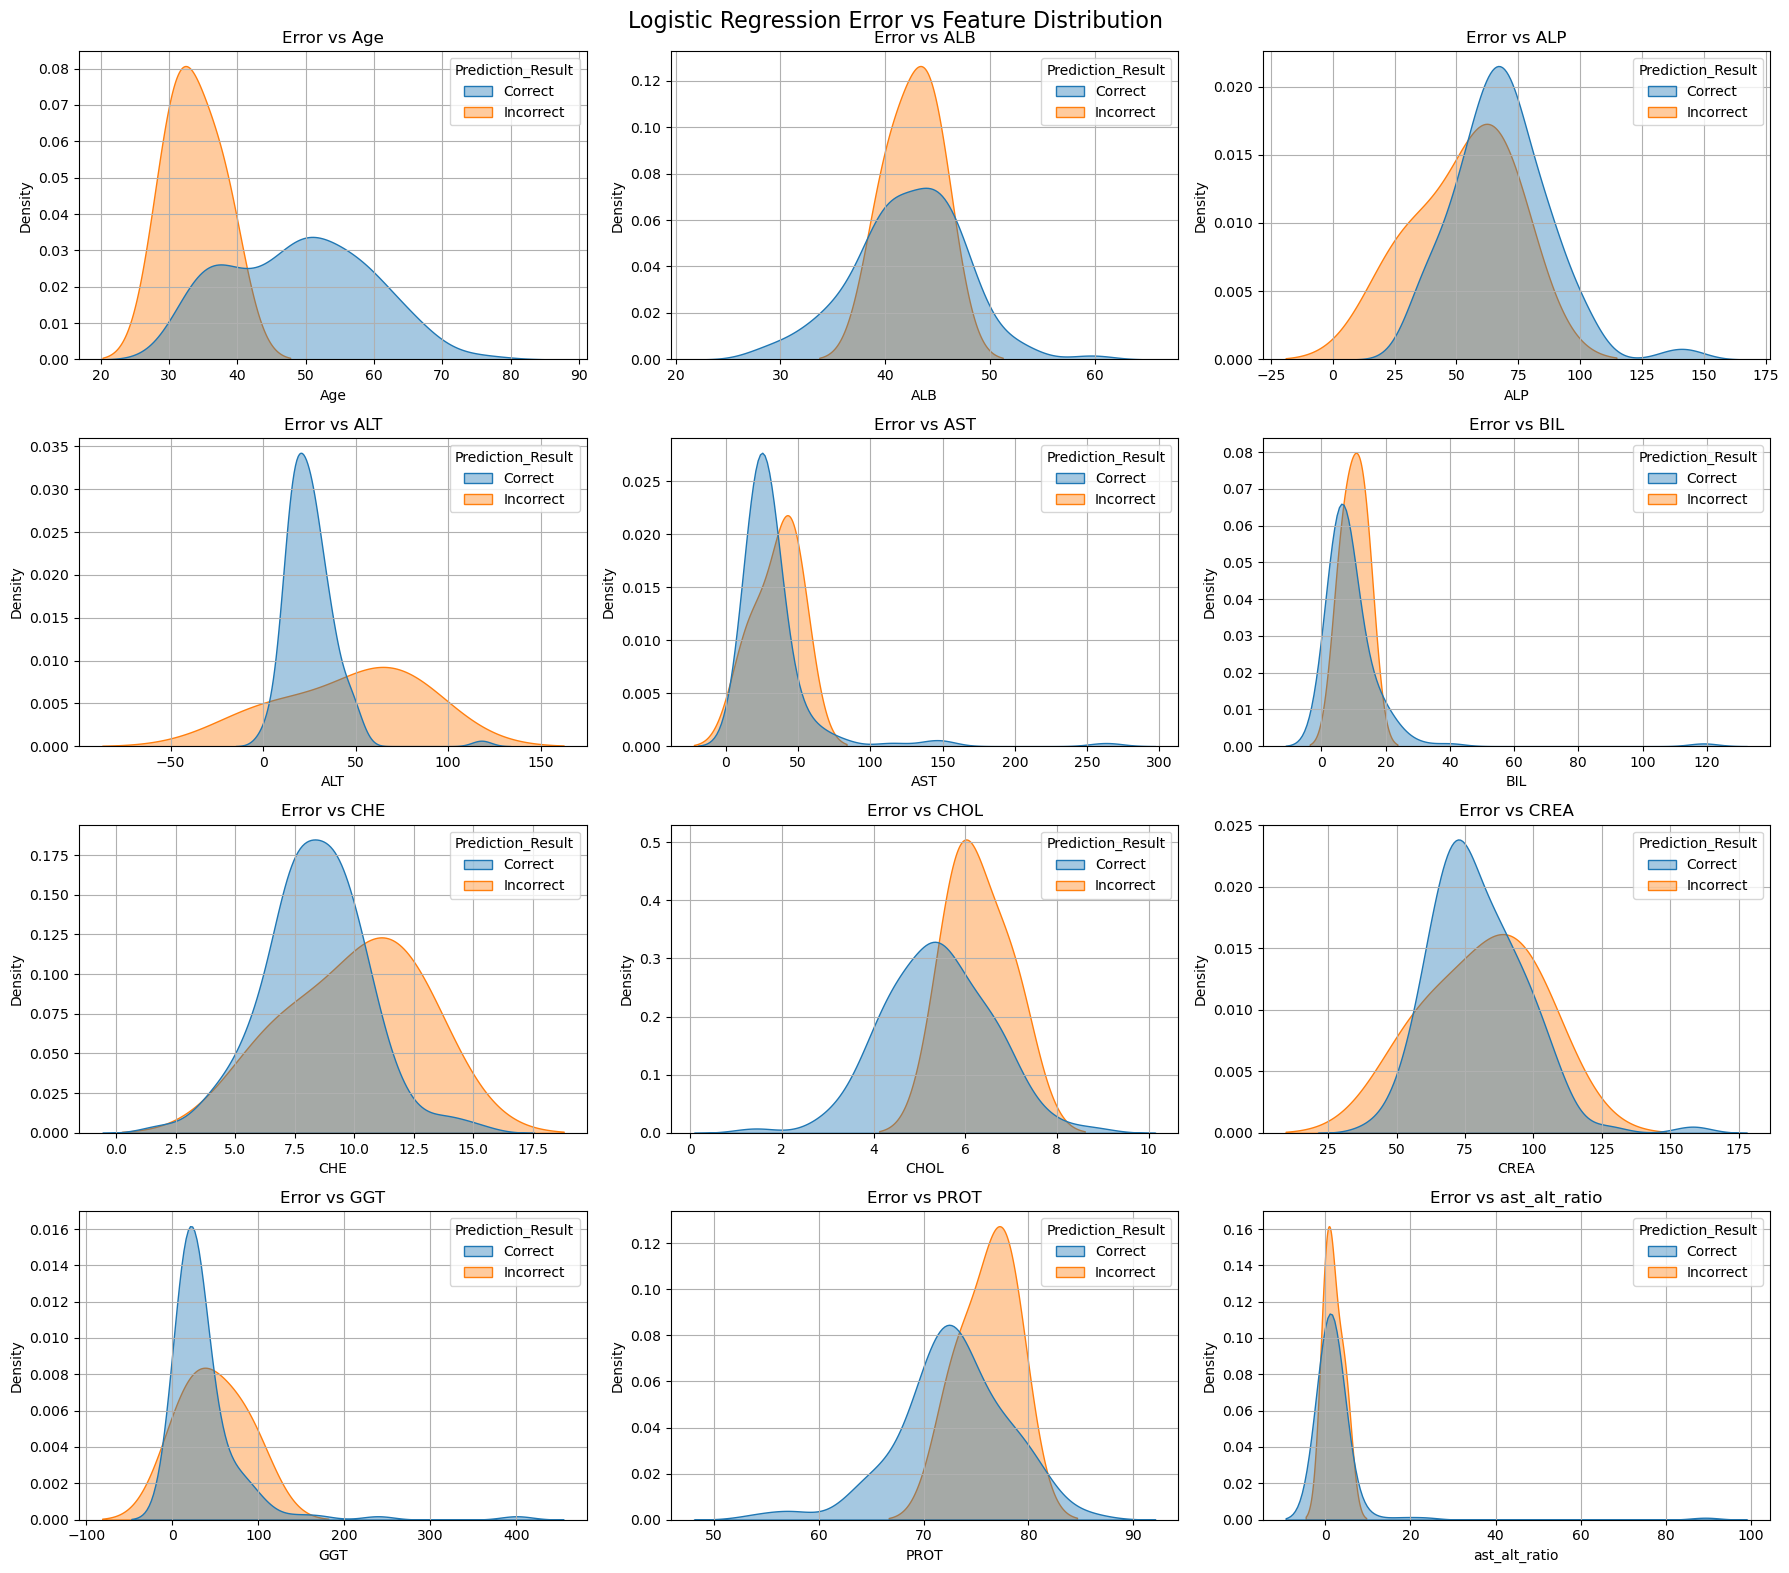

In [10]:
# choosing selected features to inspect (sex is left out as it is binary)
features_to_plot = [col for col in X_train.columns if col != 'Sex']

# setting number of plots per row
plots_per_row = 3

# calculating number of rows needed
n_rows = math.ceil(len(features_to_plot) / plots_per_row)

# creating subplots
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=log_error_df,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Logistic Regression Error vs Feature Distribution',
             fontsize=16)
plt.tight_layout()
plt.show()

# Random forest

In [11]:
# defining random forest model
rf_model = RandomForestClassifier(
    n_estimators=200,        # number of trees
    max_depth=None,          # let trees grow fully
    min_samples_split=2,     # minimum samples to split
    min_samples_leaf=1,      # minimum samples per leaf
    max_features='sqrt',     # features considered per split
    class_weight='balanced',
    random_state=42,
    n_jobs=-1)

# training model
rf_model.fit(X_train, y_train)

# predictions
rf_preds = rf_model.predict(X_test)

# evaluating predictions
rf_results = classification_report(y_test, rf_preds, target_names=classes)
print(rf_results)

              precision    recall  f1-score   support

     Healthy       0.98      0.99      0.99       107
        Sick       0.93      0.87      0.90        15

    accuracy                           0.98       122
   macro avg       0.96      0.93      0.94       122
weighted avg       0.97      0.98      0.98       122



The random forest gives the same result as logistic regression: 98% accuracy, 13 of the 15 sick patients found and 1 healthy patient wrongly flagged.

# Calibration plot - Random Forest

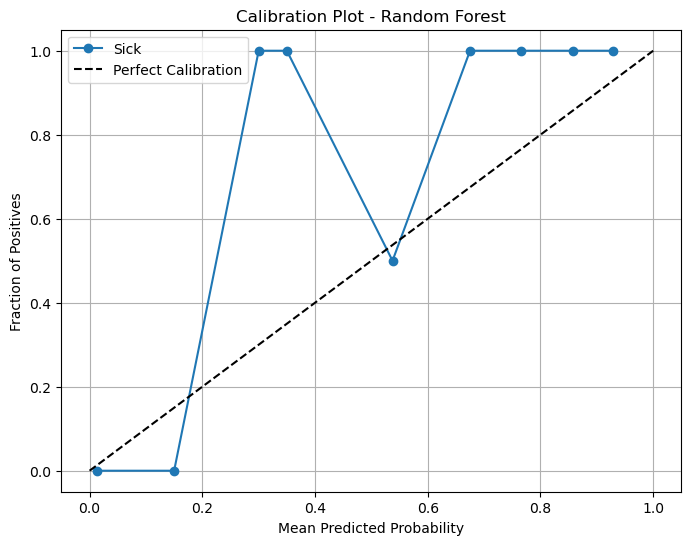

In [12]:
# getting predicted probabilities of the sick class from random forest
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# calculate calibration curve for the sick class
prob_true, prob_pred = calibration_curve(
    y_test,
    rf_probs,
    n_bins=10,
    strategy='uniform'
)

# plotting calibration curve
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Sick')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Random Forest')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature plot - random forest

Data preparation

In [13]:
# creating a copy of the test data
rf_error_df = X_test.copy()

# adding actual and predicted classes
rf_error_df['Actual_Class'] = y_test.values
rf_error_df['Predicted_Class'] = rf_preds

# checking if the prediction was correct or incorrect
rf_error_df['Prediction_Result'] = np.where(
    rf_error_df['Actual_Class'] == rf_error_df['Predicted_Class'],
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(rf_error_df['Prediction_Result'].value_counts())

Prediction_Result
Correct      119
Incorrect      3
Name: count, dtype: int64


Error plots - random forest

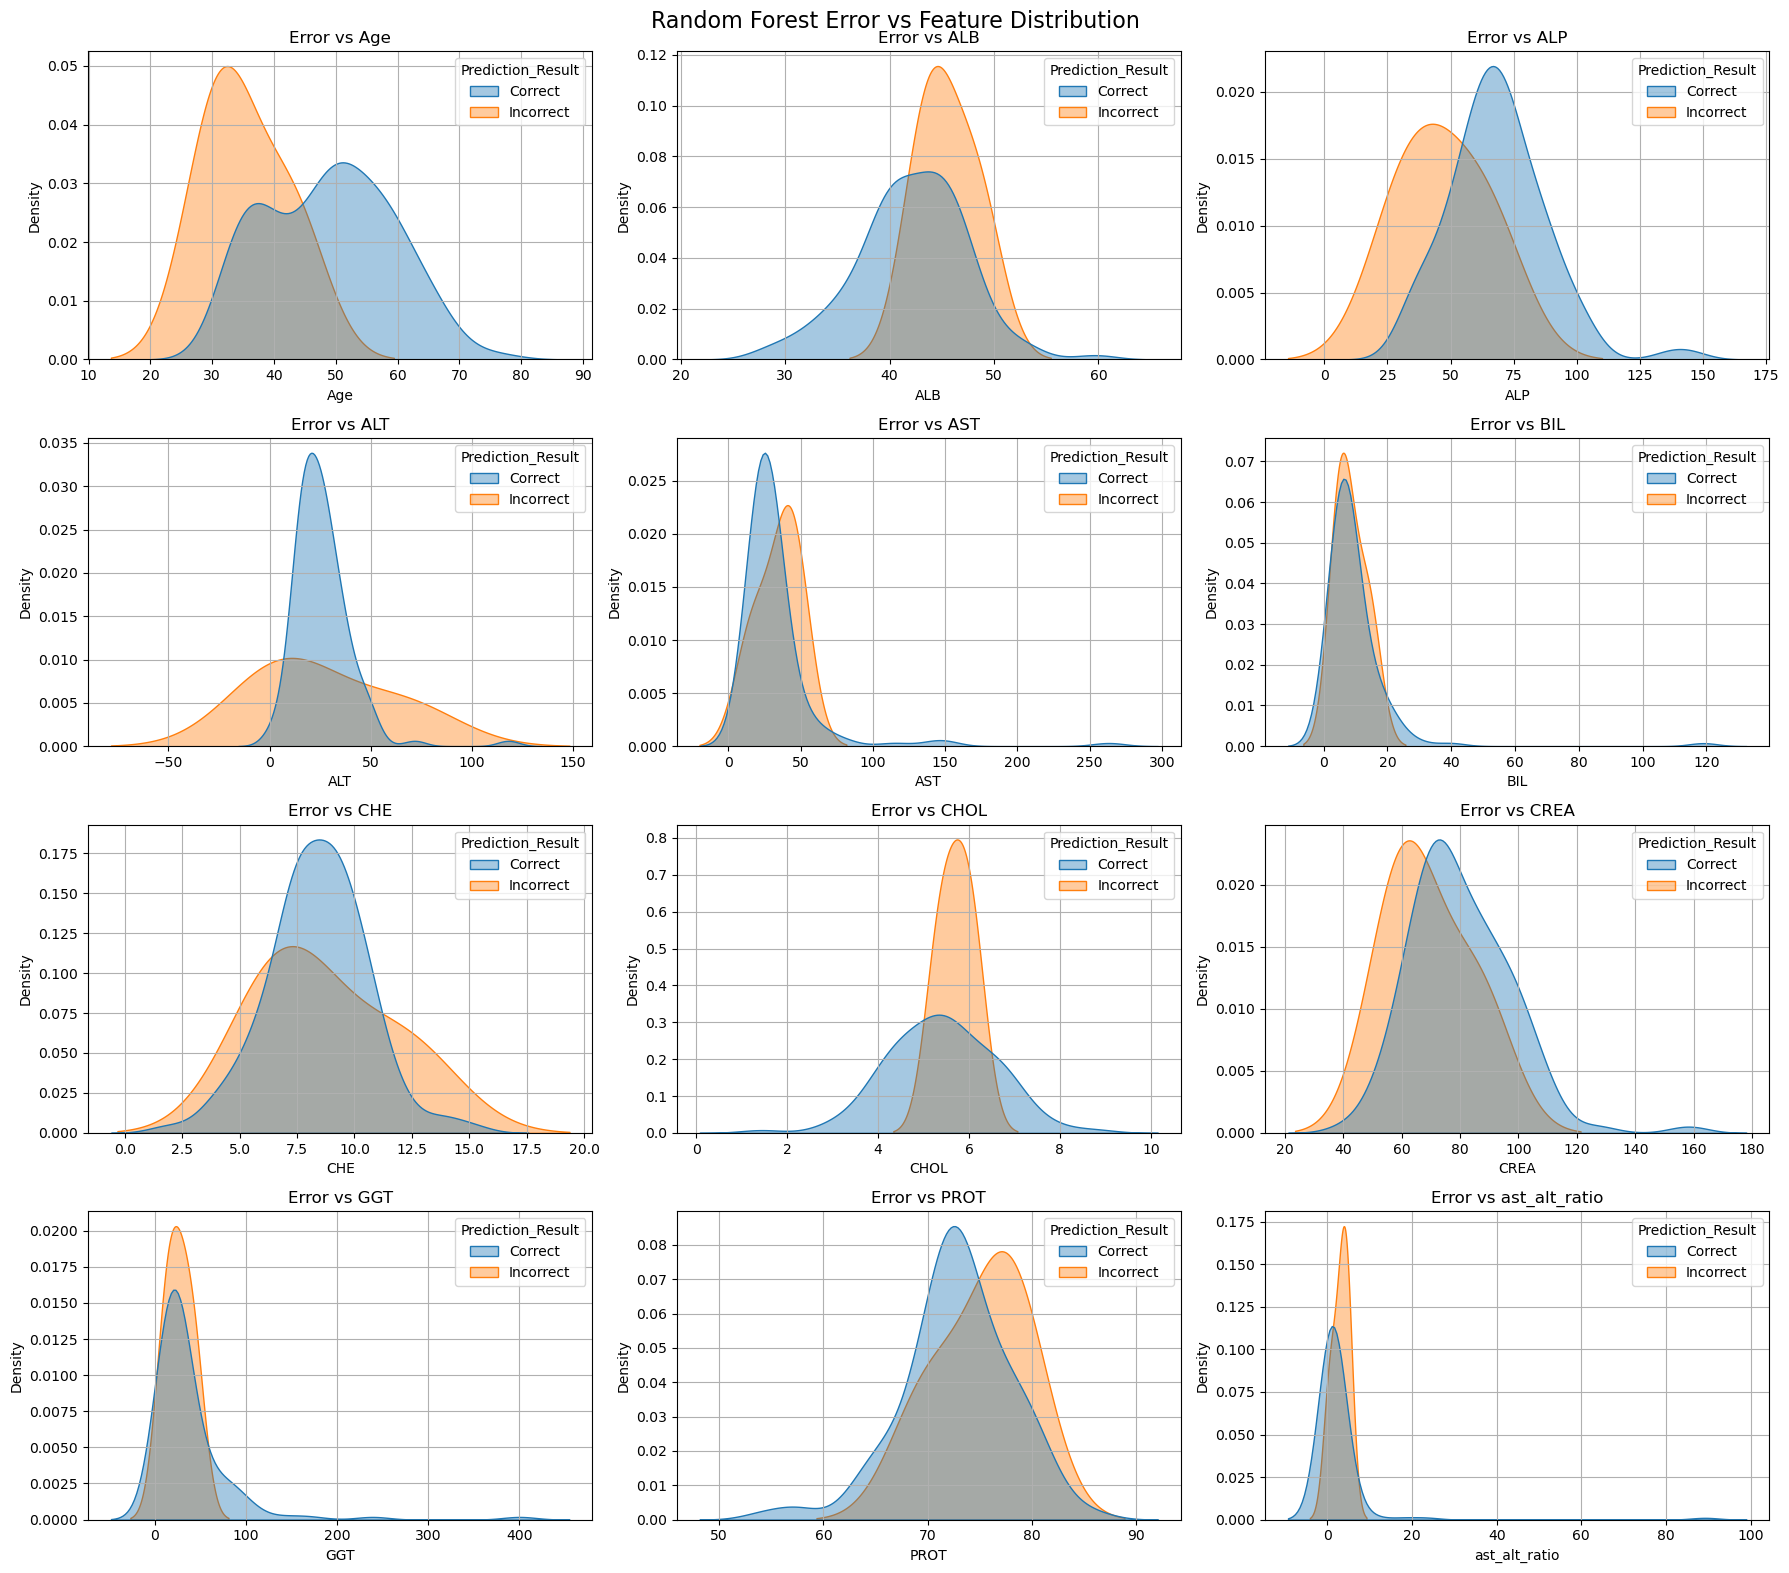

In [14]:
# creating subplots (same features and layout as logistic regression)
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=rf_error_df,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Random Forest Error vs Feature Distribution', fontsize=16)
plt.tight_layout()
plt.show()

# Decision tree

In [15]:
# train a decision tree
dt_model = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

# print decision tree evaluation metrics
print('Accuracy:', accuracy_score(y_test, dt_preds))
print(classification_report(y_test, dt_preds, target_names=classes))

Accuracy: 0.9836065573770492
              precision    recall  f1-score   support

     Healthy       1.00      0.98      0.99       107
        Sick       0.88      1.00      0.94        15

    accuracy                           0.98       122
   macro avg       0.94      0.99      0.96       122
weighted avg       0.99      0.98      0.98       122



The decision tree finds all 15 sick patients and wrongly flags 2 of the 107 healthy patients, which also gives 98% accuracy.

# Calibration plot - Decision Tree

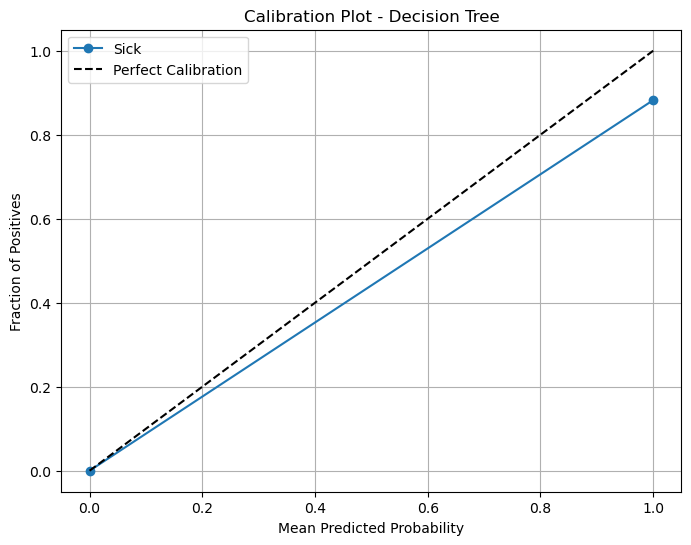

In [16]:
# getting predicted probabilities of the sick class from decision tree
dt_probs = dt_model.predict_proba(X_test)[:, 1]

# calculate calibration curve for the sick class
prob_true, prob_pred = calibration_curve(
    y_test,
    dt_probs,
    n_bins=10,
    strategy='uniform'
)

# plotting calibration curve
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Sick')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Decision Tree')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# **Summary**

All three models separate healthy and sick patients well, with 98% accuracy and no synthetic patients. Logistic regression and random forest each miss 2 sick patients. The decision tree misses none but flags 2 healthy patients.

These results have limits:

- The test set has only 15 sick patients, so one extra mistake changes sick recall by about 7 points.
- The results come from a single train-test split, as in COM725. The cross-validated results in `experiment_datasets.ipynb` are lower (macro F1 0.86 to 0.90 without the AST/ALT ratio).
- The missing values were filled with the median of all patients before the split. This affects 31 values.